# Abalone Classification: Logistic Regression, PCA, and SVM

This notebook completes both parts of the practical:

- **Part A:** Load and inspect the dataset, perform EDA, encode features, split and scale data, train Logistic Regression, perform PCA, inspect explained variance, plot PCA-based Logistic Regression coefficients, and evaluate the PCA-based model.
- **Part B:** Train RBF-kernel SVM models on the original standardized features and on the PCA features, then compare all four models.

## Before you start

1. Put `abalone.csv` in the **same folder** as this notebook.
2. Run the cells from top to bottom.
3. The standard UCI Abalone CSV is headerless; the loader below also handles a file with column headers.

**Target definition:** `Rings` is numeric, so this notebook groups it into three classes: Low (8 or fewer), Medium (9–10), and High (11 or more). These are experiment-specific class boundaries, not official biological categories. `Rings` is excluded from the input features to prevent target leakage.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

# Make plots readable
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TEST_SIZE = 0.20
CLASS_ORDER = ["Low rings (<=8)", "Medium rings (9-10)", "High rings (>=11)"]

## 2. Load and inspect the Abalone dataset

In [2]:
file_path = Path("abalone.csv")
if not file_path.exists():
    raise FileNotFoundError(
        "Could not find 'abalone.csv'. Place it in the same folder as this notebook, "
        "or update file_path to the correct location."
    )

column_names = [
    "Sex", "Length", "Diameter", "Height", "Whole weight",
    "Shucked weight", "Viscera weight", "Shell weight", "Rings"
]

# Detect whether the first row is a header or a data row.
preview = pd.read_csv(file_path, header=None, nrows=1)
first_cell = str(preview.iloc[0, 0]).strip().lower()
if first_cell == "sex":
    df = pd.read_csv(file_path)
else:
    df = pd.read_csv(file_path, header=None, names=column_names)

# Normalize likely header variations, e.g. whole_weight -> whole weight.
df.columns = [
    str(col).strip().lower().replace("_", " ").replace("-", " ")
    for col in df.columns
]

required_columns = [
    "sex", "length", "diameter", "height", "whole weight",
    "shucked weight", "viscera weight", "shell weight", "rings"
]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(
        f"The CSV is missing expected Abalone columns: {missing_columns}. "
        f"Columns found: {df.columns.tolist()}"
    )

numeric_columns = [
    "length", "diameter", "height", "whole weight",
    "shucked weight", "viscera weight", "shell weight", "rings"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["sex"] = df["sex"].astype("string").str.strip().str.upper()
rows_before = len(df)
df = df.dropna(subset=required_columns).copy()
# Remove empty or invalid sex values, if any.
df = df[df["sex"].isin(["M", "F", "I"])].copy()

print(f"Rows before cleaning: {rows_before}")
print(f"Rows after cleaning:  {len(df)}")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())
print("\nDataset information:")
df.info()
print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing values"))

Rows before cleaning: 4177
Rows after cleaning:  4177
Dataset shape: (4177, 9)

First five rows:


,sex,length,diameter,height,whole weight,shucked weight,viscera weight,shell weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sex             4177 non-null   string 
 1   length          4177 non-null   float64
 2   diameter        4177 non-null   float64
 3   height          4177 non-null   float64
 4   whole weight    4177 non-null   float64
 5   shucked weight  4177 non-null   float64
 6   viscera weight  4177 non-null   float64
 7   shell weight    4177 non-null   float64
 8   rings           4177 non-null   int64  
dtypes: float64(7), int64(1), string(1)
memory usage: 293.8 KB

Missing values by column:


,Missing values
sex,0
length,0
diameter,0
height,0
whole weight,0
shucked weight,0
viscera weight,0
shell weight,0
rings,0


## 3. Exploratory Data Analysis (EDA)

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sex,4177,3,M,1528,NaN,NaN,NaN,NaN,NaN,NaN,NaN
length,4177.0,NaN,NaN,NaN,0.523992,0.120093,0.075,0.45,0.545,0.615,0.815
diameter,4177.0,NaN,NaN,NaN,0.407881,0.09924,0.055,0.35,0.425,0.48,0.65
height,4177.0,NaN,NaN,NaN,0.139516,0.041827,0.0,0.115,0.14,0.165,1.13
whole weight,4177.0,NaN,NaN,NaN,0.828742,0.490389,0.002,0.4415,0.7995,1.153,2.8255
shucked weight,4177.0,NaN,NaN,NaN,0.359367,0.221963,0.001,0.186,0.336,0.502,1.488
viscera weight,4177.0,NaN,NaN,NaN,0.180594,0.109614,0.0005,0.0935,0.171,0.253,0.76
shell weight,4177.0,NaN,NaN,NaN,0.238831,0.139203,0.0015,0.13,0.234,0.329,1.005
rings,4177.0,NaN,NaN,NaN,9.933684,3.224169,1.0,8.0,9.0,11.0,29.0


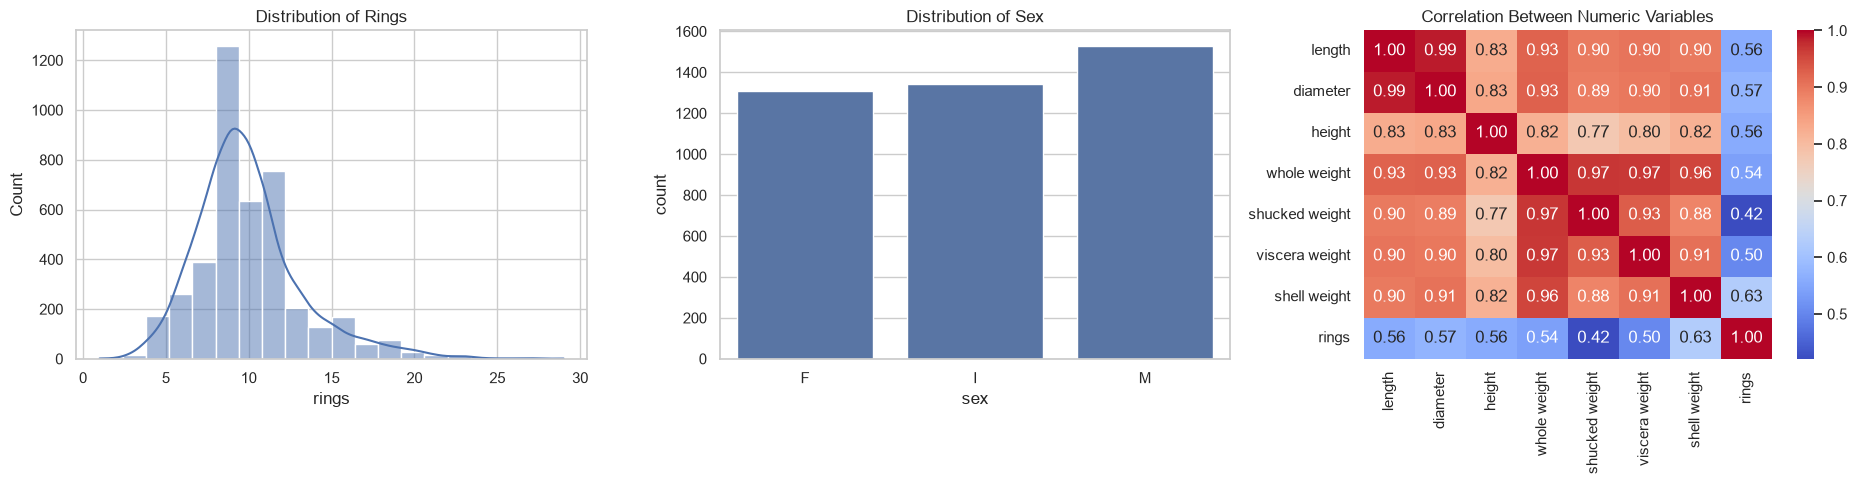

In [3]:
print("Summary statistics:")
display(df.describe(include="all").T)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.histplot(data=df, x="rings", bins=20, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Rings")

sns.countplot(data=df, x="sex", order=sorted(df["sex"].unique()), ax=axes[1])
axes[1].set_title("Distribution of Sex")

sns.heatmap(
    df[numeric_columns].corr(), annot=True, cmap="coolwarm", fmt=".2f",
    ax=axes[2], cbar=True
)
axes[2].set_title("Correlation Between Numeric Variables")

plt.tight_layout()
plt.show()

## 4. Create the classification target and encode categorical inputs

Target class distribution:


,Count
ring_class,
Low rings (<=8),1407
Medium rings (9-10),1323
High rings (>=11),1447


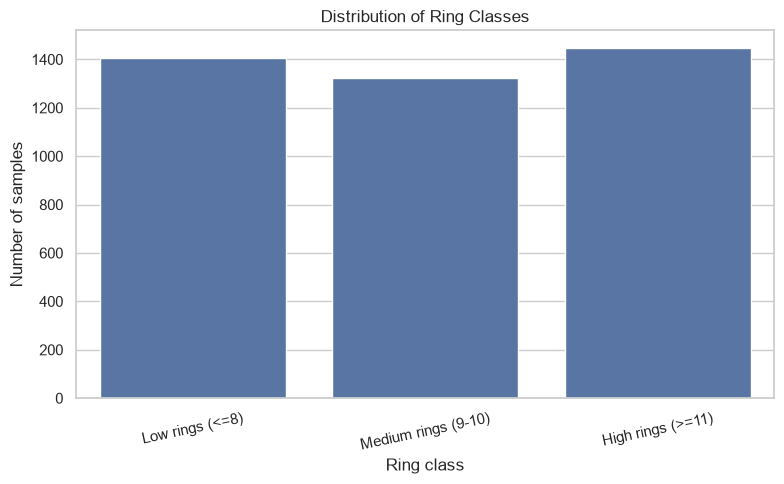

Input feature shape: (4177, 9)
Target shape: (4177,)
Encoded feature names: ['length', 'diameter', 'height', 'whole weight', 'shucked weight', 'viscera weight', 'shell weight', 'sex_I', 'sex_M']


,length,diameter,height,whole weight,shucked weight,viscera weight,shell weight,sex_I,sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,0,1
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,0,1
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,0,0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,0,1
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,1,0


In [4]:
df["ring_class"] = pd.cut(
    df["rings"],
    bins=[-np.inf, 8, 10, np.inf],
    labels=CLASS_ORDER
)

print("Target class distribution:")
display(df["ring_class"].value_counts().reindex(CLASS_ORDER).to_frame("Count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="ring_class", order=CLASS_ORDER)
plt.title("Distribution of Ring Classes")
plt.xlabel("Ring class")
plt.ylabel("Number of samples")
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()

# Rings is used to construct the target, so it must not be included in X.
X = df.drop(columns=["rings", "ring_class"])
y = df["ring_class"].astype(str)

# One-hot encode Sex; drop_first avoids a redundant dummy column.
X = pd.get_dummies(X, columns=["sex"], drop_first=True, dtype=int)

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("Encoded feature names:", X.columns.tolist())
display(X.head())

## 5. Train/test split and standardization

In [5]:
# A single stratified split is reused for all four model experiments.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

# Fit the scaler on training data only; apply the fitted scaler to test data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape:", X_train_scaled.shape)
print("Testing set shape: ", X_test_scaled.shape)
print("Training class distribution:")
print(y_train.value_counts().reindex(CLASS_ORDER))
print("Testing class distribution:")
print(y_test.value_counts().reindex(CLASS_ORDER))

Training set shape: (3341, 9)
Testing set shape:  (836, 9)
Training class distribution:
ring_class
Low rings (<=8)        1126
Medium rings (9-10)    1058
High rings (>=11)      1157
Name: count, dtype: int64
Testing class distribution:
ring_class
Low rings (<=8)        281
Medium rings (9-10)    265
High rings (>=11)      290
Name: count, dtype: int64


## 6. Evaluation helper

In [6]:
results = []


def evaluate_model(name, model, X_train_input, X_test_input, y_train, y_test):
    '''Fit a model, print its metrics, save summary scores, and return predictions.'''
    model.fit(X_train_input, y_train)
    predictions = model.predict(X_test_input)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test, predictions, labels=CLASS_ORDER,
        average="macro", zero_division=0
    )

    print("\n" + "=" * 72)
    print(name)
    print("=" * 72)
    print(f"Accuracy: {accuracy:.4f}")
    print("\nConfusion matrix (rows = actual, columns = predicted):")
    cm = confusion_matrix(y_test, predictions, labels=CLASS_ORDER)
    display(pd.DataFrame(cm, index=CLASS_ORDER, columns=CLASS_ORDER))

    print("\nClassification report:")
    print(classification_report(
        y_test, predictions,
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        zero_division=0
    ))

    results.append({"Model": name, "Accuracy": accuracy, "Macro F1": macro_f1})
    return predictions

## Part A — Logistic Regression

### 7. Logistic Regression with original standardized features

In [7]:
lr_original = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
lr_original_predictions = evaluate_model(
    "Logistic Regression - Original Features",
    lr_original,
    X_train_scaled, X_test_scaled,
    y_train, y_test
)


Logistic Regression - Original Features
Accuracy: 0.6459

Confusion matrix (rows = actual, columns = predicted):


,Low rings (<=8),Medium rings (9-10),High rings (>=11)
Low rings (<=8),219,56,6
Medium rings (9-10),56,144,65
High rings (>=11),26,87,177



Classification report:
                     precision    recall  f1-score   support

    Low rings (<=8)       0.73      0.78      0.75       281
Medium rings (9-10)       0.50      0.54      0.52       265
  High rings (>=11)       0.71      0.61      0.66       290

           accuracy                           0.65       836
          macro avg       0.65      0.64      0.64       836
       weighted avg       0.65      0.65      0.65       836



### 8. PCA and explained variance

Number of original features: 9
Number of selected principal components: 4

pca_model.explained_variance_ratio_:
[0.75620787 0.12597864 0.04535667 0.03232059]

Variance explained by each PC (%):
[75.62078655 12.59786375  4.53566691  3.23205855]

Total variance retained: 95.99%


,Principal Component,Variance Ratio,Variance Explained (%),Cumulative Variance (%)
0,PC1,0.756208,75.620787,75.620787
1,PC2,0.125979,12.597864,88.218650
2,PC3,0.045357,4.535667,92.754317
3,PC4,0.032321,3.232059,95.986376


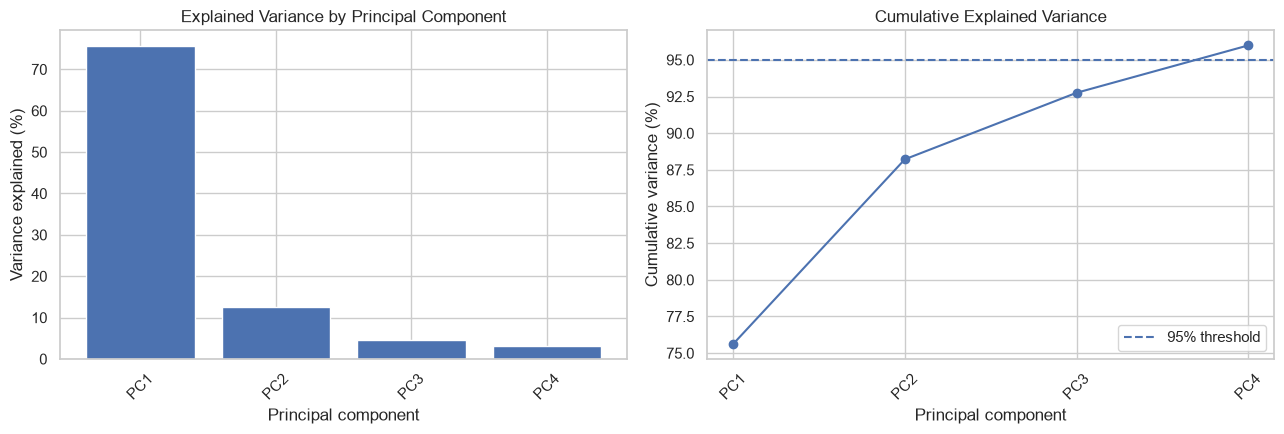

In [8]:
# Keep the smallest number of PCs that explain at least 95% of training-set variance.
pca_model = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pca_model.fit_transform(X_train_scaled)
X_test_pca = pca_model.transform(X_test_scaled)

print("Number of original features:", X_train_scaled.shape[1])
print("Number of selected principal components:", pca_model.n_components_)
print("\npca_model.explained_variance_ratio_:")
print(pca_model.explained_variance_ratio_)
print("\nVariance explained by each PC (%):")
print(pca_model.explained_variance_ratio_ * 100)
print(f"\nTotal variance retained: {pca_model.explained_variance_ratio_.sum() * 100:.2f}%")

cumulative_variance = np.cumsum(pca_model.explained_variance_ratio_)
variance_table = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(pca_model.n_components_)],
    "Variance Ratio": pca_model.explained_variance_ratio_,
    "Variance Explained (%)": pca_model.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})
display(variance_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pc_names = [f"PC{i+1}" for i in range(pca_model.n_components_)]
axes[0].bar(pc_names, pca_model.explained_variance_ratio_ * 100)
axes[0].set_title("Explained Variance by Principal Component")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Variance explained (%)")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(pc_names, cumulative_variance * 100, marker="o")
axes[1].axhline(95, linestyle="--", label="95% threshold")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Cumulative variance (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation:** `explained_variance_ratio_[i]` is the proportion of total variance explained by principal component `i`. For example, `0.40` means 40%. The cumulative plot shows how much variance is retained as more components are included. PCA is fitted on training data only; the test data is transformed using the same fitted PCA model.

### 9. Logistic Regression with PCA features

In [9]:
lr_pca = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
lr_pca_predictions = evaluate_model(
    "Logistic Regression - PCA Features",
    lr_pca,
    X_train_pca, X_test_pca,
    y_train, y_test
)


Logistic Regression - PCA Features
Accuracy: 0.5849

Confusion matrix (rows = actual, columns = predicted):


,Low rings (<=8),Medium rings (9-10),High rings (>=11)
Low rings (<=8),215,39,27
Medium rings (9-10),58,83,124
High rings (>=11),32,67,191



Classification report:
                     precision    recall  f1-score   support

    Low rings (<=8)       0.70      0.77      0.73       281
Medium rings (9-10)       0.44      0.31      0.37       265
  High rings (>=11)       0.56      0.66      0.60       290

           accuracy                           0.58       836
          macro avg       0.57      0.58      0.57       836
       weighted avg       0.57      0.58      0.57       836



### 10. Heatmap of Logistic Regression coefficients for principal components

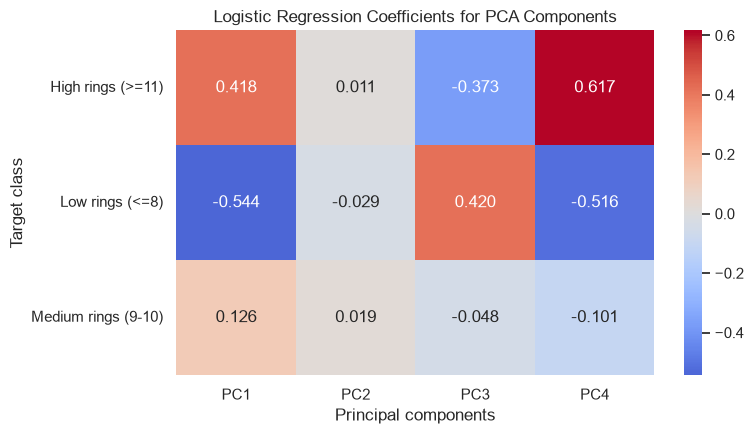

In [10]:
pc_names = [f"PC{i+1}" for i in range(pca_model.n_components_)]

plt.figure(figsize=(max(8, 1.0 * len(pc_names)), 4.5))
sns.heatmap(
    lr_pca.coef_,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    xticklabels=pc_names,
    yticklabels=lr_pca.classes_
)
plt.title("Logistic Regression Coefficients for PCA Components")
plt.xlabel("Principal components")
plt.ylabel("Target class")
plt.tight_layout()
plt.show()

**Heatmap interpretation:** Each row corresponds to a class and each column to a principal component. A positive coefficient raises that class's linear score, while a negative coefficient lowers it, all else equal. These are model coefficients in PCA space, not direct coefficients for the original physical measurements.

## Part B — Support Vector Machine (SVM)

### 11. SVM with original standardized features

In [11]:
# RBF: nonlinear kernel; C controls regularization; gamma='scale' uses feature variance.
svm_original = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_original_predictions = evaluate_model(
    "SVM (RBF) - Original Features",
    svm_original,
    X_train_scaled, X_test_scaled,
    y_train, y_test
)


SVM (RBF) - Original Features
Accuracy: 0.6651

Confusion matrix (rows = actual, columns = predicted):


,Low rings (<=8),Medium rings (9-10),High rings (>=11)
Low rings (<=8),211,63,7
Medium rings (9-10),39,158,68
High rings (>=11),21,82,187



Classification report:
                     precision    recall  f1-score   support

    Low rings (<=8)       0.78      0.75      0.76       281
Medium rings (9-10)       0.52      0.60      0.56       265
  High rings (>=11)       0.71      0.64      0.68       290

           accuracy                           0.67       836
          macro avg       0.67      0.66      0.67       836
       weighted avg       0.67      0.67      0.67       836



### 12. SVM with PCA features

In [12]:
svm_pca = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_pca_predictions = evaluate_model(
    "SVM (RBF) - PCA Features",
    svm_pca,
    X_train_pca, X_test_pca,
    y_train, y_test
)


SVM (RBF) - PCA Features
Accuracy: 0.6268

Confusion matrix (rows = actual, columns = predicted):


,Low rings (<=8),Medium rings (9-10),High rings (>=11)
Low rings (<=8),207,49,25
Medium rings (9-10),35,133,97
High rings (>=11),22,84,184



Classification report:
                     precision    recall  f1-score   support

    Low rings (<=8)       0.78      0.74      0.76       281
Medium rings (9-10)       0.50      0.50      0.50       265
  High rings (>=11)       0.60      0.63      0.62       290

           accuracy                           0.63       836
          macro avg       0.63      0.62      0.63       836
       weighted avg       0.63      0.63      0.63       836



## 13. Final comparison of all four models

Model comparison (sorted by test accuracy, then macro F1):


,Model,Accuracy,Macro F1
0,SVM (RBF) - Original Features,0.6651,0.6661
1,Logistic Regression - Original Features,0.6459,0.6441
2,SVM (RBF) - PCA Features,0.6268,0.6260
3,Logistic Regression - PCA Features,0.5849,0.5680



Best model by test accuracy: SVM (RBF) - Original Features
Test accuracy: 0.6651
Macro F1-score: 0.6661


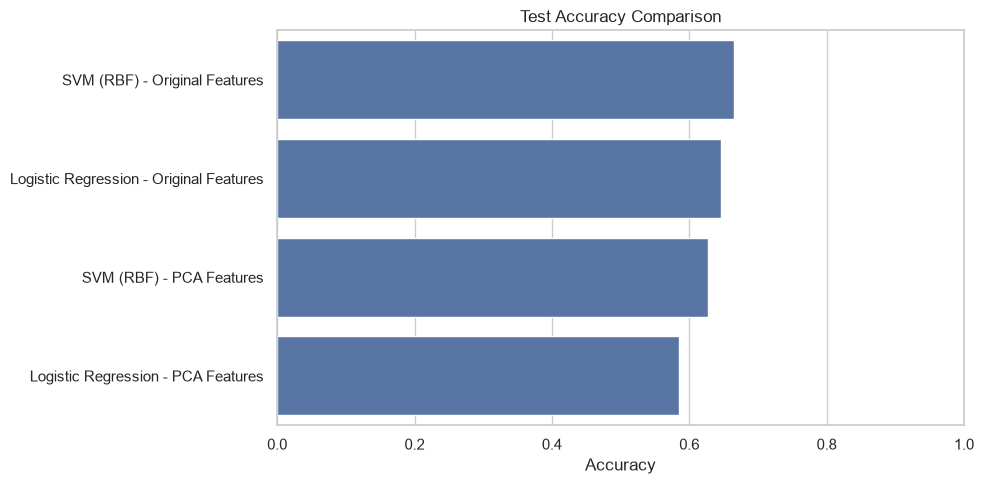

In [13]:
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    by=["Accuracy", "Macro F1"], ascending=False
).reset_index(drop=True)

print("Model comparison (sorted by test accuracy, then macro F1):")
display(comparison.style.format({"Accuracy": "{:.4f}", "Macro F1": "{:.4f}"}))

best_model = comparison.iloc[0]
print("\nBest model by test accuracy:", best_model["Model"])
print(f"Test accuracy: {best_model['Accuracy']:.4f}")
print(f"Macro F1-score: {best_model['Macro F1']:.4f}")

plt.figure(figsize=(10, 5))
sns.barplot(data=comparison, x="Accuracy", y="Model")
plt.xlim(0, 1)
plt.title("Test Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 14. Conclusion template

After running all cells, complete this conclusion using the actual output (do not guess the scores):

> The Abalone dataset was inspected and explored using summary statistics and visualizations. The categorical `Sex` feature was one-hot encoded. Since `Rings` is numeric, it was converted into three target classes: Low (8 or fewer), Medium (9–10), and High (11 or more). A stratified 80:20 train/test split was used for all models. Standardization and PCA were fitted using only training data to prevent test-data leakage.
>
> Logistic Regression and RBF-kernel SVM were each evaluated on the original standardized features and on PCA-transformed features. PCA retained **[enter percentage]%** of the training-data variance using **[enter number]** components. Based on the held-out test set, **[enter best model]** achieved the highest accuracy of **[enter accuracy]** and macro F1 of **[enter macro F1]**. Results show whether PCA helped or reduced classification performance for this split.

### Notes

- Accuracy alone can hide poor performance on minority classes; inspect per-class precision, recall, and F1-score too.
- The class boundaries are an experiment design choice. If your instructor specifies different boundaries, update `pd.cut` and `CLASS_ORDER` consistently.
- Results may vary if the dataset, preprocessing, split seed, or model parameters change.